# Scary Stochastics, Week 5: Thompson Sampling
## Notebook 1 of 3 — How the Vampire Decides

### The problem

Every night, five kinds of victim are out and about, and a hungry vampire gets one bite. How much blood a bite yields is random, and the vampire doesn't know which kind of victim is richest. Bite a favorite every night and you may never discover a better one. Sample everyone forever and you starve. This is the **multi-armed bandit** problem: each victim class is an 'arm' to pull, and the trade-off is **explore vs. exploit**.

### Thompson Sampling in three steps

1. **Believe.** For each victim class, keep a probability distribution over its *average yield* — wide when you know little, narrow when you've bitten a lot.
2. **Draw.** Each night, take one random draw from each of tonight's five beliefs and bite the class with the highest draw.
3. **Update.** Watch how much blood you got and sharpen that class's belief.

Uncertain classes produce wildly varying draws, so they win the occasional night and get explored. Classes known to be poor stop winning. Exploration fades on its own.

### Seven victims, seven distributions

Each class has a different yield distribution, so each needs its own kind of belief (a conjugate update, so everything stays in closed form). The vampire knows each class's *family* but not its parameters. Yields are in pints; Gamma classes use (shape, rate), so Gamma(2, 2) averages 1 pint.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Vampire palette (extends the series palette with blood burgundy, midnight indigo and ivory)
PALETTE = {
    "burgundy": "#7A0C1E",  # blood burgundy - the Thompson Sampling vampire
    "indigo":   "#232A5C",  # midnight indigo
    "ivory":    "#FFFFF0",  # ivory - plot panels and light text
    "red":      "#C8102E",
    "orange":   "#E8741C",
    "rust":     "#B5451B",
    "purple":   "#3B2145",
    "mustard":  "#D9A404",
    "teal":     "#2A7F7F",
    "silver":   "#9AA5B4",
    "blue":     "#4682B4",
    "black":    "#1B1B1B",
    "cream":    "#FBF3E1",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["ivory"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

### The town, the simulator, and the vampire's brain

This block holds the whole model: the seven true yield distributions, the belief updates behind Thompson Sampling, and a simulator that runs many vampires in parallel. Skim it now and come back later — the visuals below show what it does.

In [2]:
# ---------------------------------------------------------------------------
# The town and its seven victim classes
# ---------------------------------------------------------------------------
CLASSES = ["Night Nurse", "Town Drunk", "Grandma", "Insomniac", "College Student", "Priest", "Sleepwalker"]
DISTS = ["Poisson(5)", "Normal(7, 2)", "Pareto(1.5)", "Gamma(2, 2)", "Poisson(10)", "Gamma(1, 1)", "Log-normal"]
CLASS_COLORS = [PALETTE["blue"], PALETTE["mustard"], PALETTE["rust"], PALETTE["purple"],
                PALETTE["orange"], PALETTE["silver"], PALETTE["teal"]]

K = 7                  # victim classes in town
N_NIGHTLY = 5          # classes on offer each night
TOWN_SIZE = 2500       # people in town: the hunter is 1 in 2,500 on a calm night
WARY_SCALE = 450.0     # every 450 pints drained adds +1 to the town's wariness
HAZARD_CAP = 0.05      # hunter chance per bite never exceeds 5%

PAR_ALPHA, PAR_XM = 1.5, 2.0      # Grandma: Pareto tail index and minimum yield
LN_MU, LN_SIGMA = 1.4, 0.7        # Sleepwalker: log-normal parameters
CAP = 40.0                        # cap on a sampled "expected yield" (Pareto can have a huge mean)

# Rates are "rate" (not "scale") for the Gamma classes, so Gamma(2, 2) averages 1 pint
TRUE_MEAN = np.array([5.0, 7.0, PAR_ALPHA * PAR_XM / (PAR_ALPHA - 1), 1.0, 10.0, 1.0,
                      np.exp(LN_MU + LN_SIGMA ** 2 / 2)])

def draw_yield(arm, rng):
    """Pints of blood from one bite on each vampire's chosen class (arm is an int array)."""
    y = np.empty(len(arm))
    for c in range(K):
        m = arm == c
        k = int(m.sum())
        if k == 0:
            continue
        if c == 0:   y[m] = rng.poisson(5.0, k)
        elif c == 1: y[m] = np.maximum(rng.normal(7.0, 2.0, k), 0)
        elif c == 2: y[m] = PAR_XM * (1 + rng.pareto(PAR_ALPHA, k))   # classic Pareto
        elif c == 3: y[m] = rng.gamma(2.0, 1 / 2.0, k)
        elif c == 4: y[m] = rng.poisson(10.0, k)
        elif c == 5: y[m] = rng.gamma(1.0, 1 / 1.0, k)
        else:        y[m] = rng.lognormal(LN_MU, LN_SIGMA, k)
    return y

# ---------------------------------------------------------------------------
# The vampire's beliefs: one conjugate posterior per class.
# n = bites so far, s = total pints, sl = total log-yield (Pareto: log(y / min yield))
# ---------------------------------------------------------------------------
def posterior_mean_draw(n, s, sl, rng):
    """One random draw of each class's EXPECTED yield from the vampire's current beliefs."""
    out = np.empty(n.shape)
    for c in (0, 4):   # Poisson classes: Gamma belief on the rate
        out[..., c] = rng.gamma(1.0 + s[..., c], 1.0 / (0.1 + n[..., c]))
    prec = 1 / 10.0 ** 2 + n[..., 1] / 2.0 ** 2    # Town Drunk: Normal belief on the mean (SD known)
    mean = (5.0 / 10.0 ** 2 + s[..., 1] / 2.0 ** 2) / prec
    out[..., 1] = rng.normal(mean, 1 / np.sqrt(prec))
    alpha = rng.gamma(1.0 + n[..., 2], 1.0 / (0.5 + sl[..., 2]))   # Grandma: Gamma belief on the tail index
    out[..., 2] = np.where(alpha > 1.05,
                           np.minimum(alpha * PAR_XM / np.maximum(alpha - 1, 1e-9), CAP), CAP)
    for c, shape in ((3, 2.0), (5, 1.0)):      # Gamma classes: Gamma belief on the rate (shape known)
        beta = rng.gamma(2.0 + shape * n[..., c], 1.0 / (1.0 + s[..., c]))
        out[..., c] = np.minimum(shape / beta, CAP)
    prec = 1 / 2.0 ** 2 + n[..., 6] / LN_SIGMA ** 2    # Sleepwalker: Normal belief on the log-scale mean
    mean = (1.0 / 2.0 ** 2 + sl[..., 6] / LN_SIGMA ** 2) / prec
    out[..., 6] = np.exp(rng.normal(mean, 1 / np.sqrt(prec)) + LN_SIGMA ** 2 / 2)
    return out

def pol_ts(n, s, sl, t, rng):
    """Thompson Sampling: score each class by one random draw from its posterior."""
    return posterior_mean_draw(n, s, sl, rng)

# ---------------------------------------------------------------------------
# The simulator: many vampires hunt in parallel (one row per vampire)
# ---------------------------------------------------------------------------
def simulate(policy, R, T, seed, hunter=False, snap=()):
    rng = np.random.default_rng(seed)
    n, s, sl = np.zeros((R, K)), np.zeros((R, K)), np.zeros((R, K))
    alive, drained, rows = np.ones(R, bool), np.zeros(R), np.arange(R)
    arm_log = np.full((R, T), -1, dtype=np.int8)
    y_log = np.zeros((R, T), dtype=np.float32)
    drained_log = np.zeros((R, T), dtype=np.float32)
    alive_log = np.zeros((R, T), dtype=bool)
    died_log = np.zeros((R, T), dtype=bool)
    regret = np.zeros((R, T))
    snaps = {}
    for t in range(T):
        if not alive.any():
            break
        # Five of the seven classes are on offer tonight (a fresh random five per vampire)
        cmask = np.zeros((R, K), bool)
        np.put_along_axis(cmask, np.argsort(rng.random((R, K)), axis=1)[:, :N_NIGHTLY], True, axis=1)
        arm = np.where(cmask, policy(n, s, sl, t, rng), -np.inf).argmax(axis=1)
        y = draw_yield(arm, rng)
        best = np.where(cmask, TRUE_MEAN, -np.inf).max(axis=1)
        # The hunter: 1 in TOWN_SIZE per bite, multiplied by the town's wariness
        wariness = 1 + drained / WARY_SCALE
        died = np.zeros(R, bool)
        if hunter:
            died = alive & (rng.random(R) < np.minimum(wariness / TOWN_SIZE, HAZARD_CAP))
        bite = alive & ~died
        idx, a, yy = rows[bite], arm[bite], y[bite]
        lg = np.log(np.maximum(yy, 1e-9))
        n[idx, a] += 1
        s[idx, a] += yy
        sl[idx, a] += np.where(a == 2, lg - np.log(PAR_XM), lg)
        arm_log[:, t] = np.where(alive, arm, -1)
        y_log[:, t] = np.where(bite, y, 0)
        drained_log[:, t] = drained
        alive_log[:, t] = alive
        died_log[:, t] = died
        regret[:, t] = np.where(alive, best - TRUE_MEAN[arm], 0)
        drained = drained + np.where(bite, y, 0)
        alive = bite
        if (t + 1) in snap:
            snaps[t + 1] = (n.copy(), s.copy(), sl.copy())
    return {"arm": arm_log, "y": y_log, "drained": drained_log, "alive": alive_log,
            "died": died_log, "regret": regret, "snaps": snaps}

### Visual 1 — The seven victims

These are the true yield distributions the vampire never sees. Dashed lines mark each average. Three things to notice: the Insomniac and Priest are nearly worthless (about 1 pint), the College Student is the richest (10), and Grandma has a **heavy tail** — usually modest, occasionally enormous (the plot cuts off at 25 pints).

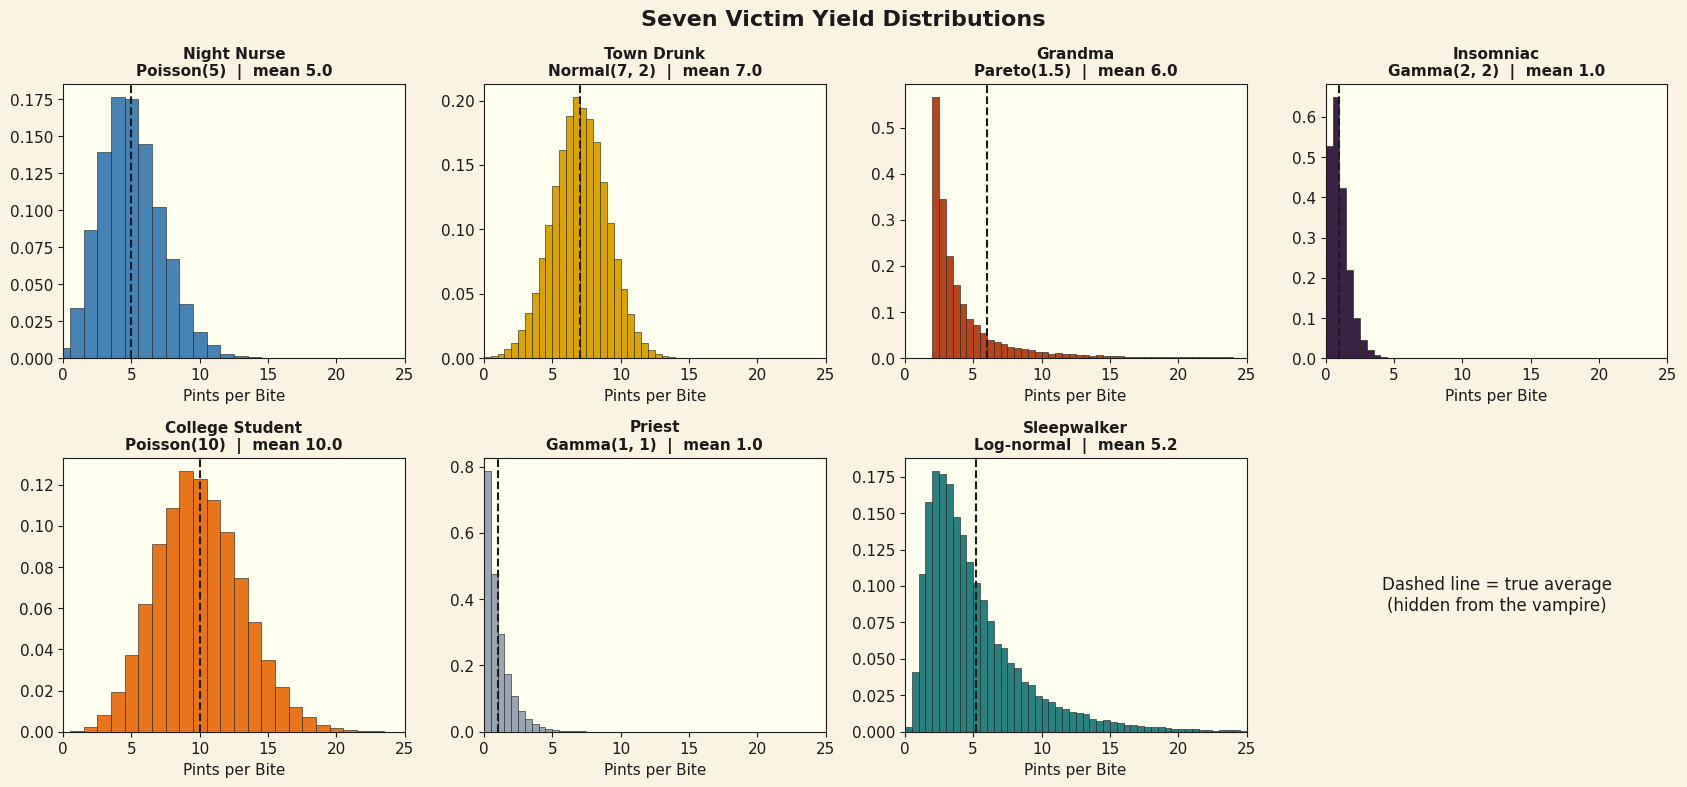

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for c, ax in enumerate(axes.flat[:K]):
    d = draw_yield(np.full(40000, c), rng)
    bins = np.arange(-0.5, 26.5, 1.0) if c in (0, 4) else np.linspace(0, 26, 53)
    w = np.ones(len(d)) / len(d) / (bins[1] - bins[0])      # density over ALL draws, even clipped ones
    ax.hist(d, bins=bins, weights=w, color=CLASS_COLORS[c], edgecolor=PALETTE["black"], linewidth=0.4)
    ax.axvline(TRUE_MEAN[c], color=PALETTE["black"], linestyle="--", linewidth=1.5)
    ax.set_xlim(0, 25)
    ax.set_title(f"{CLASSES[c]}\n{DISTS[c]}  |  mean {TRUE_MEAN[c]:.1f}", fontsize=11)
    ax.set_xlabel("Pints per Bite")
axes.flat[7].axis("off")
axes.flat[7].text(0.5, 0.5, "Dashed line = true average\n(hidden from the vampire)",
                  ha="center", va="center", fontsize=12)
fig.suptitle("Seven Victim Yield Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("01_yield_distributions.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Watch one vampire learn

One Thompson Sampling vampire hunts for 200 nights, and we save snapshots of its beliefs at nights 1, 10, 25, 50 and 200. The table afterwards compares what it ended up believing to the truth.

In [4]:
SNAPS = [1, 10, 25, 50, 200]
walk = simulate(pol_ts, R=1, T=200, seed=11, snap=SNAPS)

n200, s200, sl200 = walk["snaps"][200]
final = posterior_mean_draw(np.tile(n200, (4000, 1)), np.tile(s200, (4000, 1)),
                            np.tile(sl200, (4000, 1)), np.random.default_rng(0))
pd.DataFrame({"Class": CLASSES, "Bites in 200 nights": n200[0].astype(int),
              "True average": TRUE_MEAN.round(1),
              "Believed average": final.mean(axis=0).round(1)})

,Class,Bites in 200 nights,True average,Believed average
0,Night Nurse,3,5.0,2.9
1,Town Drunk,20,7.0,7.0
2,Grandma,45,6.0,8.6
3,Insomniac,1,1.0,2.1
4,College Student,114,10.0,9.6
5,Priest,1,1.0,0.6
6,Sleepwalker,16,5.2,5.5


### Visual 2 — One night's decision

Night 26. The College Student stayed home, so tonight's five are the Nurse, Drunk, Grandma, Priest and Sleepwalker. Each shaded curve is the vampire's belief about that class's average yield after 25 nights. The dashed line is tonight's **single random draw** from that belief. The highest draw wins the bite — not necessarily the highest average. A wide belief (like Grandma's) can win through luck, and that is exploration.

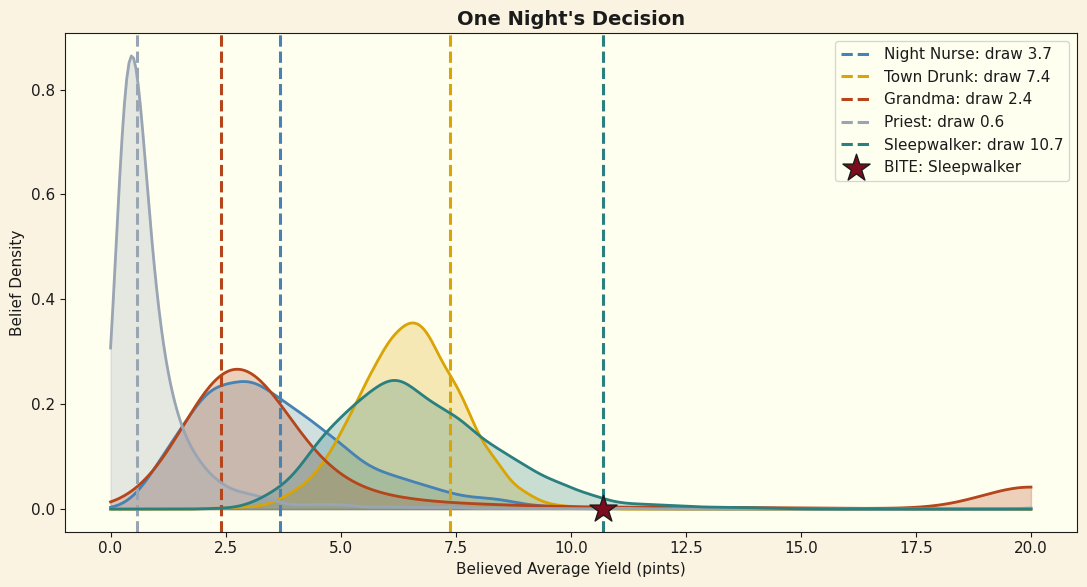

In [5]:
n25, s25, sl25 = walk["snaps"][25]
cand = np.array([0, 1, 2, 5, 6])          # tonight's five (the College Student stayed home)
rng = np.random.default_rng(3)
post = posterior_mean_draw(np.tile(n25, (4000, 1)), np.tile(s25, (4000, 1)), np.tile(sl25, (4000, 1)), rng)
tonight = posterior_mean_draw(n25, s25, sl25, rng)[0]
winner = cand[np.argmax(tonight[cand])]

xs = np.linspace(0, 20, 400)
fig, ax = plt.subplots(figsize=(11, 6))
for c in cand:
    dens = stats.gaussian_kde(np.clip(post[:, c], 0, 20))(xs)
    ax.fill_between(xs, dens, color=CLASS_COLORS[c], alpha=0.25)
    ax.plot(xs, dens, color=CLASS_COLORS[c], linewidth=2)
    ax.axvline(min(tonight[c], 19.8), color=CLASS_COLORS[c], linestyle="--", linewidth=2.2,
               label=f"{CLASSES[c]}: draw {tonight[c]:.1f}")
ax.scatter(min(tonight[winner], 19.8), 0, marker="*", s=420, color=PALETTE["burgundy"],
           edgecolors=PALETTE["black"], zorder=5, clip_on=False, label=f"BITE: {CLASSES[winner]}")
ax.set_xlabel("Believed Average Yield (pints)")
ax.set_ylabel("Belief Density")
ax.set_title("One Night's Decision")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("02_one_nights_decision.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 3 — Beliefs sharpen over time

The same vampire's beliefs about all seven classes at four moments. Triangles mark the true averages. After one night almost everything is guesswork. By night 50 the vampire has pinned down the classes it keeps biting, while the classes it abandoned stay vague — and that's fine, because it no longer needs them.

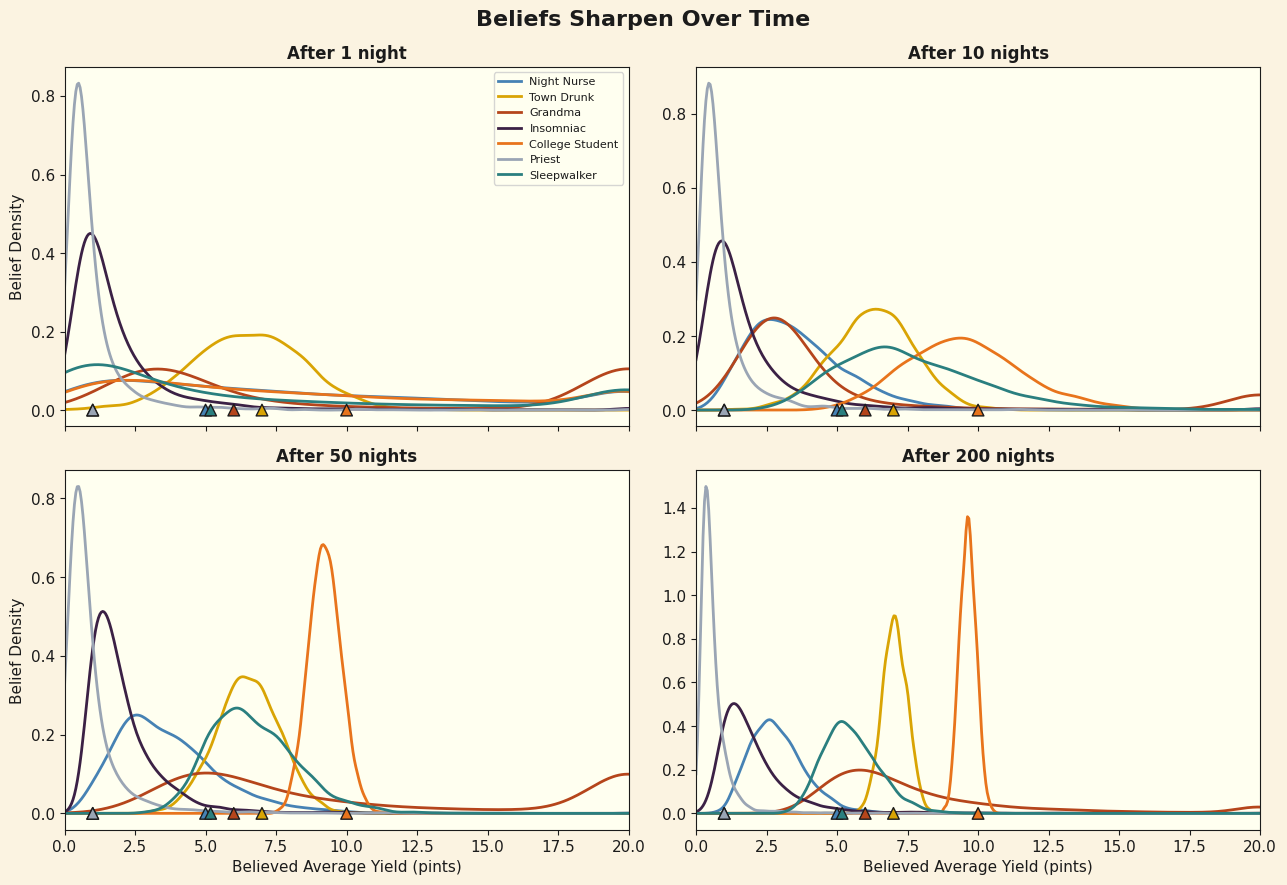

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
xs = np.linspace(0, 20, 400)
for ax, t in zip(axes.flat, [1, 10, 50, 200]):
    nn, ss, ll = walk["snaps"][t]
    post = posterior_mean_draw(np.tile(nn, (3000, 1)), np.tile(ss, (3000, 1)), np.tile(ll, (3000, 1)),
                               np.random.default_rng(t))
    for c in range(K):
        dens = stats.gaussian_kde(np.clip(post[:, c], 0, 20))(xs)
        ax.plot(xs, dens, color=CLASS_COLORS[c], linewidth=2, label=CLASSES[c])
    ax.scatter(TRUE_MEAN, np.zeros(K), marker="^", s=70, color=CLASS_COLORS, edgecolors=PALETTE["black"],
               zorder=5, clip_on=False)
    ax.set_title(f"After {t} night" + ("s" if t > 1 else ""), fontsize=12)
    ax.set_xlim(0, 20)
for ax in axes[1]:
    ax.set_xlabel("Believed Average Yield (pints)")
for ax in axes[:, 0]:
    ax.set_ylabel("Belief Density")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Beliefs Sharpen Over Time", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("03_beliefs_sharpen.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Up next

Notebook 2 pits this vampire against five rivals, then introduces the vampire hunter.